# Collaborative Filtering

Compare explicit-rating matrix factorization with implicit-feedback ALS on the same temporal split. Hyperparameters are selected on validation; both final models are then compared with popularity on the held-out test split.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "scripts"))   # notebooks/ -> project root -> scripts

import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from recutils import load_split, to_sets, rank_topk, evaluate_topk

NAME, K, REL, SEED = "sample_10pct", 10, 4.0, 42

S = load_split(NAME)
train, val, test = S["train"], S["val"], S["test"]
n_users = int(S["user_map"].u.max()) + 1
n_items = int(S["item_map"].i.max()) + 1
print(f"{n_users:,} users | {n_items:,} items | train {len(train):,} | val {len(val):,} | test {len(test):,}")

def seen_matrix(*dfs):
    """Sparse 0/1 matrix of (user, item) pairs the user already has; used to hide them from recommendations."""
    d = pd.concat(dfs)
    return sp.csr_matrix((np.ones(len(d), dtype=np.float32), (d.u.values, d.i.values)),
                         shape=(n_users, n_items))

seen_train = seen_matrix(train)
rel_val = to_sets(val[val.rating >= REL])
print("validation users with >=1 relevant item:", len(rel_val))

20,093 users | 17,241 items | train 2,919,680 | val 137,197 | test 137,197
validation users with >=1 relevant item: 18392


## 1. Explicit matrix factorization

The first model predicts numeric ratings using user/item factors and bias terms.


In [2]:
def _half_step(M, X, b, mu, lam):
    """Solve for one side given the other.
    M: CSR (rows to solve x fixed side) of ratings | X: fixed vectors | b: fixed biases."""
    n_rows, k = M.shape[0], X.shape[1]
    Xa  = np.hstack([X, np.ones((X.shape[0], 1))])      # [vector, 1]
    out = np.zeros((n_rows, k + 1))                     # [vector, bias]
    eye = np.eye(k + 1)
    indptr, indices, data = M.indptr, M.indices, M.data
    for r in range(n_rows):
        s, e = indptr[r], indptr[r + 1]
        n = e - s
        if n == 0:
            continue
        js = indices[s:e]
        F  = Xa[js]
        y  = data[s:e] - mu - b[js]
        out[r] = np.linalg.solve(F.T @ F + lam * n * eye, F.T @ y)
    return out[:, :k], out[:, k]


def rmse(df, P, Q, bu, bi, mu):
    pred = mu + bu[df.u.values] + bi[df.i.values] + np.einsum("ij,ij->i", P[df.u.values], Q[df.i.values])
    return float(np.sqrt(np.mean((np.clip(pred, 0.5, 5.0) - df.rating.values) ** 2)))


def fit_als(df, k=32, lam=0.1, n_iter=15, eval_fn=None, eval_every=0, rmse_on=val, seed=SEED):
    rng = np.random.default_rng(seed)
    mu  = df.rating.mean()
    R   = sp.csr_matrix((df.rating.values.astype(np.float64), (df.u.values, df.i.values)),
                        shape=(n_users, n_items))
    Rt  = R.T.tocsr()
    Q   = rng.normal(0, 0.1, (n_items, k))
    bi  = np.zeros(n_items)
    hist, t0 = [], time.time()
    for it in range(1, n_iter + 1):
        P, bu = _half_step(R,  Q, bi, mu, lam)     # users given items
        Q, bi = _half_step(Rt, P, bu, mu, lam)     # items given users
        row = {"iter": it, "sec": round(time.time() - t0)}
        if rmse_on is not None:
            row["val_rmse"] = rmse(rmse_on, P, Q, bu, bi, mu)
        if eval_fn and eval_every and (it % eval_every == 0 or it == n_iter):
            row.update(eval_fn(P, Q, bu, bi))
        hist.append(row)
    return {"P": P, "Q": Q, "bu": bu, "bi": bi, "mu": mu}, pd.DataFrame(hist)


def make_explicit_eval(rel, seen_csr):
    """Ranking evaluation for a factor model. Ranking score = b_item + p_user·q_item
    (mu and b_user are constant per user, so they can't change that user's order)."""
    def f(P, Q, bu, bi):
        Q32, bi32 = Q.astype(np.float32), bi.astype(np.float32)
        score_fn  = lambda ub: P[ub].astype(np.float32) @ Q32.T + bi32
        return evaluate_topk(rank_topk(score_fn, rel.keys(), seen_csr, K), rel, n_items, K)
    return f

eval_explicit_val = make_explicit_eval(rel_val, seen_train)


### Baselines


In [3]:
mu = train.rating.mean()
print("RMSE, predict global mean for everything:", round(float(np.sqrt(((val.rating - mu) ** 2).mean())), 4))

counts = np.bincount(train.i, minlength=n_items).astype(np.float32)
counts_liked = np.bincount(train.i[train.rating >= REL], minlength=n_items).astype(np.float32)
n_train = counts
n_pos = counts_liked
u_pos = np.bincount(train.u[train.rating >= REL], minlength=n_users)
u_has_pos = u_pos > 0
pop_ranked = rank_topk(lambda ub: np.tile(counts, (len(ub), 1)), rel_val.keys(), seen_train, K)
pop = evaluate_topk(pop_ranked, rel_val, n_items, K)

m0, h0 = fit_als(train, k=0, lam=0.1, n_iter=8, eval_fn=eval_explicit_val, eval_every=8)
print(h0.tail(1).round(4).to_string(index=False))

results = {"popularity": pop}
results["bias-only (k=0)"] = {**h0.iloc[-1].drop(["iter", "sec"]).to_dict()}
pd.DataFrame(results).T.round(4)


RMSE, predict global mean for everything: 1.0534
 iter  sec  val_rmse  Recall@10  NDCG@10  HitRate@10  Coverage
    8    7    0.8834        0.0      0.0      0.0001    0.0008


,Recall@10,NDCG@10,HitRate@10,Coverage,val_rmse
popularity,0.0574,0.0415,0.1620,0.0137,NaN
bias-only (k=0),0.0000,0.0000,0.0001,0.0008,0.8834


### Fit and tune

Track validation RMSE and ranking metrics, then compare a small grid of factor counts and regularization strengths.


In [4]:
mf_model, mf_history = fit_als(train, k=32, lam=0.1, n_iter=15, eval_fn=eval_explicit_val, eval_every=3)
mf_history.round(4)


,iter,sec,val_rmse,Recall@10,NDCG@10,HitRate@10,Coverage
0,1,2,0.8946,NaN,NaN,NaN,NaN
1,2,4,0.8707,NaN,NaN,NaN,NaN
2,3,6,0.8512,0.0001,0.0001,0.0004,0.0446
3,4,13,0.8429,NaN,NaN,NaN,NaN
4,5,15,0.8390,NaN,NaN,NaN,NaN
5,6,17,0.8372,0.0003,0.0002,0.0011,0.0620
6,7,22,0.8362,NaN,NaN,NaN,NaN
7,8,24,0.8356,NaN,NaN,NaN,NaN
8,9,26,0.8352,0.0004,0.0002,0.0015,0.0670
9,10,32,0.8349,NaN,NaN,NaN,NaN


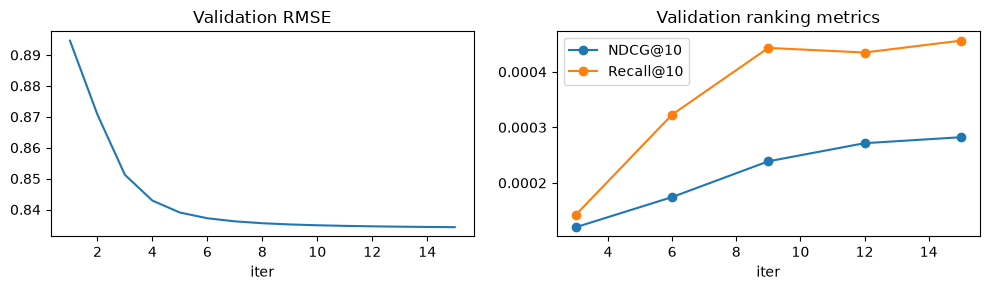

,Recall@10,NDCG@10,HitRate@10,Coverage,val_rmse
popularity,0.0574,0.0415,0.1620,0.0137,NaN
bias-only (k=0),0.0000,0.0000,0.0001,0.0008,0.8834
"MF k=32, λ=0.1",0.0005,0.0003,0.0016,0.0718,NaN


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
mf_history.plot(x="iter", y="val_rmse", ax=ax[0], title="Validation RMSE"); ax[0].legend().remove()
mf_history.dropna(subset=["NDCG@10"]).plot(x="iter", y=["NDCG@10", "Recall@10"], ax=ax[1], marker="o", title="Validation ranking metrics")
plt.tight_layout(); plt.show()

results["MF k=32, λ=0.1"] = mf_history.iloc[-1].drop(["iter", "sec", "val_rmse"]).to_dict()
pd.DataFrame(results).T.round(4)


In [6]:
grid = [(32, 0.05), (32, 0.2), (16, 0.1), (64, 0.1)]     # (32, 0.1) already done above
rows = [{"k": 32, "lam": 0.1, "val_rmse": mf_history.val_rmse.iloc[-1],
         **mf_history.iloc[-1][["Recall@10", "NDCG@10", "HitRate@10", "Coverage"]].to_dict()}]

for k, lam in grid:
    t = time.time()
    mdl, h = fit_als(train, k=k, lam=lam, n_iter=15, eval_fn=eval_explicit_val, eval_every=15)
    rows.append({"k": k, "lam": lam, "val_rmse": h.val_rmse.iloc[-1],
                 **h.iloc[-1][["Recall@10", "NDCG@10", "HitRate@10", "Coverage"]].to_dict()})
    print(f"k={k:>3} λ={lam}: done in {time.time()-t:.0f}s")

explicit_sweep = pd.DataFrame(rows).sort_values("NDCG@10", ascending=False)
explicit_sweep.round(4)


k= 32 λ=0.05: done in 33s
k= 32 λ=0.2: done in 32s
k= 16 λ=0.1: done in 23s
k= 64 λ=0.1: done in 58s


,k,lam,val_rmse,Recall@10,NDCG@10,HitRate@10,Coverage
1,32,0.05,0.8314,0.0015,0.0009,0.0054,0.2635
4,64,0.10,0.8337,0.0006,0.0004,0.0023,0.0681
0,32,0.10,0.8343,0.0005,0.0003,0.0016,0.0718
3,16,0.10,0.8351,0.0003,0.0002,0.0010,0.0740
2,32,0.20,0.8757,0.0000,0.0000,0.0002,0.0037


The explicit model is retained as a benchmark. The next section uses positive interactions directly, which is better aligned with the top-K recommendation task.


## 2. Implicit-feedback ALS

Here, ratings of at least 4.0 are treated as positive interactions. Confidence, regularization and factor count are selected by validation NDCG@10.


In [7]:
def eval_scores(item_scores, rel, seen):
    score_fn = lambda ub: np.tile(item_scores, (len(ub), 1))
    return evaluate_topk(rank_topk(score_fn, rel.keys(), seen, K), rel, n_items, K)

explicit_best = explicit_sweep.sort_values("NDCG@10", ascending=False).iloc[0]
explicit_val_metrics = {
    "Recall@10": float(explicit_best["Recall@10"]),
    "NDCG@10": float(explicit_best["NDCG@10"]),
    "HitRate@10": float(explicit_best["HitRate@10"]),
    "Coverage": float(explicit_best["Coverage"]),
}

baseline_results = {
    "Popularity (all ratings)": eval_scores(counts, rel_val, seen_train),
    "Popularity (ratings >= 4)": eval_scores(counts_liked, rel_val, seen_train),
    "Explicit MF (best validation config)": explicit_val_metrics,
}
pd.DataFrame(baseline_results).T.round(4)


,Recall@10,NDCG@10,HitRate@10,Coverage
Popularity (all ratings),0.0574,0.0415,0.1620,0.0137
Popularity (ratings >= 4),0.0576,0.0419,0.1633,0.0139
Explicit MF (best validation config),0.0015,0.0009,0.0054,0.2635


In [8]:
def _implicit_half_step(M, Y, lam):
    """One side of implicit ALS. M: CSR (rows to solve x fixed side) whose data = confidence - 1."""
    n_rows, k = M.shape[0], Y.shape[1]
    YtY = Y.T @ Y
    reg = lam * np.eye(k)
    out = np.zeros((n_rows, k))
    indptr, indices, data = M.indptr, M.indices, M.data
    for r in range(n_rows):
        s, e = indptr[r], indptr[r + 1]
        if s == e:
            continue
        Yj  = Y[indices[s:e]]
        cm1 = data[s:e]
        A = YtY + (Yj.T * cm1) @ Yj + reg
        b = Yj.T @ (cm1 + 1.0)
        out[r] = np.linalg.solve(A, b)
    return out


def fit_implicit(df, mode="liked", k=32, alpha=20.0, lam=20.0, n_iter=10,
                 eval_fn=None, eval_every=0, seed=SEED):
    assert mode in ("all", "liked")
    d = df[df.rating >= REL] if mode == "liked" else df
    C  = sp.csr_matrix((np.full(len(d), float(alpha)), (d.u.values, d.i.values)), shape=(n_users, n_items))
    Ct = C.T.tocsr()
    rng = np.random.default_rng(seed)
    Q = rng.normal(0, 0.1, (n_items, k))
    hist, t0 = [], time.time()
    for it in range(1, n_iter + 1):
        P = _implicit_half_step(C,  Q, lam)
        Q = _implicit_half_step(Ct, P, lam)
        if eval_fn and eval_every and (it % eval_every == 0 or it == n_iter):
            hist.append({"iter": it, "sec": round(time.time() - t0), **eval_fn(P, Q)})
    return {"P": P, "Q": Q}, pd.DataFrame(hist)


def rank_all(P, Q, rel, seen_csr, u_has_pos, fallback_scores):
    """Top-K for every user in rel (only its keys are used).
    - movies with an all-zero vector are never recommended
    - users with no positive history get the fallback (popularity) list"""
    Q32 = Q.astype(np.float32)
    pen = np.where(np.abs(Q32).sum(axis=1) > 0, 0.0, -np.inf).astype(np.float32)
    def score_fn(ub):
        s = P[ub].astype(np.float32) @ Q32.T + pen
        cold = ~u_has_pos[ub]
        if cold.any():
            s[cold] = fallback_scores
        return s
    return rank_topk(score_fn, rel.keys(), seen_csr, K)


def make_implicit_eval(rel, seen_csr, u_has_pos, fallback_scores):
    def f(P, Q):
        return evaluate_topk(rank_all(P, Q, rel, seen_csr, u_has_pos, fallback_scores), rel, n_items, K)
    return f

eval_implicit_val = make_implicit_eval(rel_val, seen_train, u_has_pos, counts)


### Initial fit


In [9]:
m1, h1 = fit_implicit(train, "liked", k=32, alpha=20, lam=20, n_iter=10, eval_fn=eval_implicit_val, eval_every=2)
h1.round(4)


,iter,sec,Recall@10,NDCG@10,HitRate@10,Coverage
0,2,3,0.1041,0.0734,0.2723,0.1017
1,4,10,0.1090,0.0775,0.2857,0.1159
2,6,17,0.1097,0.0783,0.2889,0.1204
3,8,24,0.1100,0.0788,0.2901,0.1225
4,10,31,0.1103,0.0789,0.2895,0.1244


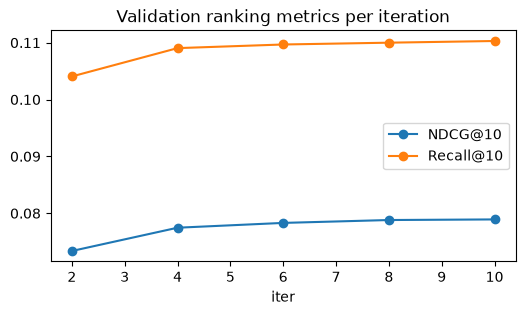

,Recall@10,NDCG@10,HitRate@10,Coverage,val_rmse
popularity,0.0574,0.0415,0.1620,0.0137,NaN
bias-only (k=0),0.0000,0.0000,0.0001,0.0008,0.8834
"MF k=32, λ=0.1",0.0005,0.0003,0.0016,0.0718,NaN
"implicit ALS, liked, k=32 a=20 lam=20",0.1103,0.0789,0.2895,0.1244,NaN


In [10]:
h1.plot(x="iter", y=["NDCG@10", "Recall@10"], marker="o", figsize=(6, 3), title="Validation ranking metrics per iteration")
plt.show()

results["implicit ALS, liked, k=32 a=20 lam=20"] = h1.iloc[-1].drop(["iter", "sec"]).to_dict()
pd.DataFrame(results).T.round(4)

### Validation sweep

The first sweep tests broad changes to the implicit-feedback settings. The follow-up values are included in the same fixed grid so every configuration is fitted and evaluated once.


In [11]:
all_cfgs = [('liked', 32, 20, 20), ('all', 32, 20, 20), ('liked', 32, 5, 20), ('liked', 32, 60, 20), ('liked', 32, 20, 5), ('liked', 32, 20, 80), ('liked', 64, 20, 20), ('liked', 64, 5, 20), ('liked', 64, 2, 20), ('liked', 64, 5, 80), ('liked', 64, 2, 80), ('liked', 64, 5, 200), ('liked', 32, 2, 20), ('liked', 32, 1, 20)]

models = {0: m1}
rows = [{
    "id": 0, "mode": "liked", "k": 32, "alpha": 20, "lam": 20,
    **h1.iloc[-1].drop(["iter", "sec"]).to_dict()
}]

for cid, (mode, k, alpha, lam) in enumerate(all_cfgs):
    if cid == 0:
        continue
    start = time.time()
    model, history = fit_implicit(
        train, mode, k, alpha, lam, n_iter=10,
        eval_fn=eval_implicit_val, eval_every=10
    )
    models[cid] = model
    rows.append({
        "id": cid, "mode": mode, "k": k,
        "alpha": alpha, "lam": lam,
        **history.iloc[-1].drop(["iter", "sec"]).to_dict()
    })
    print(
        f"id={cid} {mode} k={k} alpha={alpha} lam={lam}: "
        f"{time.time() - start:.0f}s"
    )

sweep = (
    pd.DataFrame(rows)
    .sort_values("NDCG@10", ascending=False)
    .reset_index(drop=True)
)
sweep.round(4)


id=1 all k=32 alpha=20 lam=20: 27s
id=2 liked k=32 alpha=5 lam=20: 20s
id=3 liked k=32 alpha=60 lam=20: 20s
id=4 liked k=32 alpha=20 lam=5: 20s
id=5 liked k=32 alpha=20 lam=80: 20s
id=6 liked k=64 alpha=20 lam=20: 40s
id=7 liked k=64 alpha=5 lam=20: 41s
id=8 liked k=64 alpha=2 lam=20: 41s
id=9 liked k=64 alpha=5 lam=80: 42s
id=10 liked k=64 alpha=2 lam=80: 41s
id=11 liked k=64 alpha=5 lam=200: 40s
id=12 liked k=32 alpha=2 lam=20: 20s
id=13 liked k=32 alpha=1 lam=20: 20s


,id,mode,k,alpha,lam,Recall@10,NDCG@10,HitRate@10,Coverage
0,9,liked,64,5,80,0.1282,0.0929,0.3272,0.0882
1,8,liked,64,2,20,0.1280,0.0928,0.3305,0.0839
2,10,liked,64,2,80,0.1260,0.0928,0.3203,0.0629
3,7,liked,64,5,20,0.1279,0.0920,0.3278,0.1012
4,13,liked,32,1,20,0.1223,0.0898,0.3170,0.0618
5,12,liked,32,2,20,0.1218,0.0893,0.3166,0.0691
6,2,liked,32,5,20,0.1190,0.0870,0.3092,0.0856
7,6,liked,64,20,20,0.1188,0.0832,0.3068,0.1396
8,5,liked,32,20,80,0.1121,0.0805,0.2936,0.1152
9,0,liked,32,20,20,0.1103,0.0789,0.2895,0.1244


### Selected model and item-history diagnostics

Inspect the selected model's catalogue coverage and the amount of positive training history behind its recommendations.


In [12]:
best_id = int(sweep.iloc[0]["id"])
print("best on validation:", all_cfgs[best_id])
P, Q = models[best_id]["P"], models[best_id]["Q"]

ranked = rank_all(P, Q, rel_val, seen_train, u_has_pos, counts)
rec = np.array([i for r in ranked.values() for i in r])

def summarize(c, name):
    c = c[rec]
    print(f"{name}: median {int(np.median(c))} | <5: {(c<5).mean():.3f} | <20: {(c<20).mean():.3f} | <50: {(c<50).mean():.3f}")

print("--- recommended movies ---")
summarize(n_train, "all train ratings      ")
summarize(n_pos,   "positive (>=4) ratings ")
print("catalogue medians: all", int(np.median(n_train)), "| positive", int(np.median(n_pos)))
print("distinct movies recommended:", len(set(rec.tolist())))
print("recommendations on zero-positive movies:", int((n_pos[rec] == 0).sum()))

print("\n--- movies the model cannot score ---")
val_rel  = val[val.rating >= REL]
zero_pos = n_pos == 0
few_pos  = (n_pos > 0) & (n_pos < 5)
print(f"zero positives: {zero_pos.sum():,} movies ({zero_pos.mean():.1%} of catalogue)")
print(f"   ...with >= 20 total train ratings: {(zero_pos & (n_train >= 20)).sum():,}")
print(f"   ...with no train ratings at all:   {(zero_pos & (n_train == 0)).sum():,}")
print(f"   share of relevant validation interactions on them: {zero_pos[val_rel.i.values].mean():.2%}")
print(f"1-4 positives: {few_pos.sum():,} movies; share of relevant validation interactions: {few_pos[val_rel.i.values].mean():.2%}")

print("\n--- per-user ceilings (macro, matching evaluate_topk) ---")
disc = 1 / np.log2(np.arange(2, K + 2))
cold_share, rec_c, rec_c0, ndcg_c = [], [], [], []
for items in rel_val.values():
    ids  = np.fromiter(items, dtype=np.int64)
    warm = n_pos[ids] > 0
    m, w = len(ids), int(warm.sum())
    cold_share.append(1 - w / m)
    rec_c.append(min(K, w) / m)       # best possible Recall if zero-positive movies are excluded
    rec_c0.append(min(K, m) / m)      # best possible Recall with no exclusion (only the K cap)
    ndcg_c.append(disc[:min(K, w)].sum() / disc[:min(K, m)].sum())
print("mean per-user share of relevant movies with zero positives:", round(float(np.mean(cold_share)), 4))
print("Recall@10 ceiling, with exclusion:", round(float(np.mean(rec_c)), 4), "| without:", round(float(np.mean(rec_c0)), 4))
print("NDCG@10 ceiling relative to the unrestricted ideal:", round(float(np.mean(ndcg_c)), 4))

print("\n--- users ---")
warm_users = {u: r for u, r in rel_val.items() if u_has_pos[u]}
print("users with no positive train interaction:", int((~u_has_pos).sum()),
      "| in the validation target:", len(rel_val) - len(warm_users))
print("overall       :", {k: round(float(v), 4) for k, v in evaluate_topk(ranked, rel_val, n_items, K).items()})
print("with positives:", {k: round(float(v), 4) for k, v in evaluate_topk(ranked, warm_users, n_items, K).items()})

best on validation: ('liked', 64, 5, 80)
--- recommended movies ---
all train ratings      : median 3370 | <5: 0.000 | <20: 0.000 | <50: 0.000
positive (>=4) ratings : median 2232 | <5: 0.000 | <20: 0.000 | <50: 0.000
catalogue medians: all 23 | positive 8
distinct movies recommended: 1520
recommendations on zero-positive movies: 0

--- movies the model cannot score ---
zero positives: 1,095 movies (6.4% of catalogue)
   ...with >= 20 total train ratings: 28
   ...with no train ratings at all:   5
   share of relevant validation interactions on them: 0.11%
1-4 positives: 5,666 movies; share of relevant validation interactions: 1.04%

--- per-user ceilings (macro, matching evaluate_topk) ---
mean per-user share of relevant movies with zero positives: 0.0009
Recall@10 ceiling, with exclusion: 0.9991 | without: 1.0
NDCG@10 ceiling relative to the unrestricted ideal: 0.9993

--- users ---
users with no positive train interaction: 34 | in the validation target: 6
overall       : {'Recall@10

### Nearest neighbours and an example user

These examples are illustrative; model selection is based on the aggregate validation metrics above.


In [13]:
movies = pd.read_parquet(Path("../data/interim") / NAME / "movies.parquet")
meta   = S["item_map"].merge(movies, on="movieId", how="left").set_index("i").sort_index()
Qn     = Q / (np.linalg.norm(Q, axis=1, keepdims=True) + 1e-9)

def similar(title_part, n=6, min_count=50):
    i = meta.index[meta.title.str.contains(title_part, regex=False)][0]
    if n_pos[i] == 0:
        print(f"{meta.loc[i, 'title']}: no positive training ratings, so no vector to compare.")
        return
    if n_pos[i] < min_count:
        print(f"note: only {n_pos[i]} positive ratings for this movie; its neighbours are unreliable")
    sims = Qn @ Qn[i]
    sims[n_pos < min_count] = -1
    sims[i] = -1
    top = np.argsort(-sims)[:n]
    print(f"\nClosest to: {meta.loc[i, 'title']}")
    return meta.loc[top, ["title", "genres"]].assign(cosine=sims[top].round(3))

similar("Toy Story (1995)")


Closest to: Toy Story (1995)


,title,genres,cosine
i,,,
2817,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.762
10903,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.598
4396,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,0.576
559,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical,0.575
5650,Finding Nemo (2003),Adventure|Animation|Children|Comedy,0.571
997,Willy Wonka & the Chocolate Factory (1971),Children|Comedy|Fantasy|Musical,0.563


## 3. Final test comparison

Refit the validation-selected explicit MF and implicit ALS configurations on train + validation. The baseline comparison uses all test ratings >= 4.0; the later hybrid notebook applies its separate post-2016 evaluation window.


In [14]:
best_implicit_id = int(sweep.iloc[0]["id"])
mode, k, alpha, lam = all_cfgs[best_implicit_id]
best_explicit = explicit_sweep.sort_values("NDCG@10", ascending=False).iloc[0]
best_k, best_lam = int(best_explicit["k"]), float(best_explicit["lam"])

full = pd.concat([train, val], ignore_index=True)
seen_tv = seen_matrix(train, val)
rel_test = to_sets(test[test.rating >= REL])

counts_tv = np.bincount(full.i, minlength=n_items).astype(np.float32)
liked_tv = np.bincount(
    full.i[full.rating >= REL], minlength=n_items
).astype(np.float32)
u_has_pos_full = (
    np.bincount(full.u[full.rating >= REL], minlength=n_users) > 0
)

print("Explicit MF:", {"k": best_k, "lambda": best_lam})
mf_final, _ = fit_als(full, k=best_k, lam=best_lam, n_iter=15, rmse_on=None)
mf_test = make_explicit_eval(rel_test, seen_tv)(
    mf_final["P"], mf_final["Q"], mf_final["bu"], mf_final["bi"]
)

print("Implicit ALS:", {"mode": mode, "k": k, "alpha": alpha, "lambda": lam})
als_final, _ = fit_implicit(
    full, mode, k, alpha, lam, n_iter=10
)
als_ranked_test = rank_all(
    als_final["P"], als_final["Q"], rel_test,
    seen_tv, u_has_pos_full, counts_tv
)
als_test = evaluate_topk(als_ranked_test, rel_test, n_items, K)

test_table = pd.DataFrame({
    "Popularity (all ratings)": eval_scores(counts_tv, rel_test, seen_tv),
    "Popularity (ratings >= 4)": eval_scores(liked_tv, rel_test, seen_tv),
    "Explicit MF": mf_test,
    "Implicit ALS": als_test,
}).T.round(4)

print("Test users:", len(rel_test))
test_table


Explicit MF: {'k': 32, 'lambda': 0.05}
Implicit ALS: {'mode': 'liked', 'k': 64, 'alpha': 5, 'lambda': 80}
Test users: 18544


,Recall@10,NDCG@10,HitRate@10,Coverage
Popularity (all ratings),0.0531,0.0393,0.1562,0.0147
Popularity (ratings >= 4),0.0524,0.0396,0.1564,0.0148
Explicit MF,0.0020,0.0012,0.0072,0.2628
Implicit ALS,0.1193,0.0878,0.3144,0.0904


In [16]:
import json
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

test_table.to_csv(reports_dir / "cf_baseline_test.csv")
explicit_sweep.round(4).to_csv(reports_dir / "explicit_mf_sweep_val.csv", index=False)
sweep.round(4).to_csv(reports_dir / "cf_sweep_val.csv", index=False)

config = {
    "explicit_mf": {
        "k": int(best_k), "lambda": float(best_lam)
    },
    "implicit_als": {
        "mode": mode, "k": int(k), "alpha": float(alpha),
        "lambda": float(lam), "n_iter": 10, "seed": SEED
    },
    "relevance_threshold": REL,
    "evaluation_k": K,
}
(reports_dir / "cf_baseline_config.json").write_text(
    json.dumps(config, indent=2) + "\n", encoding="utf-8"
)

print("Saved test comparison, validation sweeps and configuration to reports/.")


Saved test comparison, validation sweeps and configuration to reports/.


## Findings

Implicit ALS was the stronger collaborative-filtering model on top-10 ranking. The validation-selected configuration was positive-only interactions, 64 factors, `alpha=5`, `lambda=80`, and 10 iterations. Explicit MF remains as a comparison rather than a candidate for deployment.
